In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random as rand

In [3]:
food = pd.read_csv('Food_from_Walmart_with_healthy_474.csv') # will add more to this

In [4]:
food

,Food Name,Category,Subcategory,Serving Size,Serving Weight (g),Calories,Protein (g),Total Fat (g),Saturated Fat (g),Total Carbs (g),Dietary Fiber (g),Sugars (g),Sodium (mg),Healthy
0,Great Value Whole Milk,Dairy & Eggs,Milk,1 cup (240 mL),244,150,8.0,8.0,5.0,12,0.0,12.0,120,True
1,Great Value Large White Eggs,Dairy & Eggs,Eggs,1 large egg,50,70,6.0,5.0,1.5,0,0.0,0.0,70,True
2,Great Value Unsalted Sweet Cream Butter,Dairy & Eggs,Butter,1 tbsp (14g),14,100,0.0,11.0,7.0,0,0.0,0.0,0,False
3,Great Value Whole Wheat Bread,Bakery & Bread,Sliced Bread,1 slice (38g),38,100,4.0,1.5,0.0,19,3.0,3.0,140,True
4,Great Value Boneless Skinless Chicken Breasts,Meat & Seafood,Poultry,4 oz (112g),112,110,23.0,1.5,0.5,0,0.0,0.0,220,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
469,Marketside Choice Angus Bone-In Ribeye Steak,Meat & Seafood,Beef,4 oz (112g),112,260,20.0,20.0,8.0,0,0.0,0.0,60,False
470,Marketside Choice Angus Flat Iron Steak,Meat & Seafood,Beef,4 oz (112g),112,190,22.0,10.0,4.0,0,0.0,0.0,65,False
471,Marketside Choice Angus Tri-Tip Roast Steak,Meat & Seafood,Beef,4 oz (112g),112,170,22.0,9.0,3.5,0,0.0,0.0,55,True
472,Great Value Beef Top Round Steak,Meat & Seafood,Beef,4 oz (112g),112,130,24.0,3.0,1.0,0,0.0,0.0,50,True


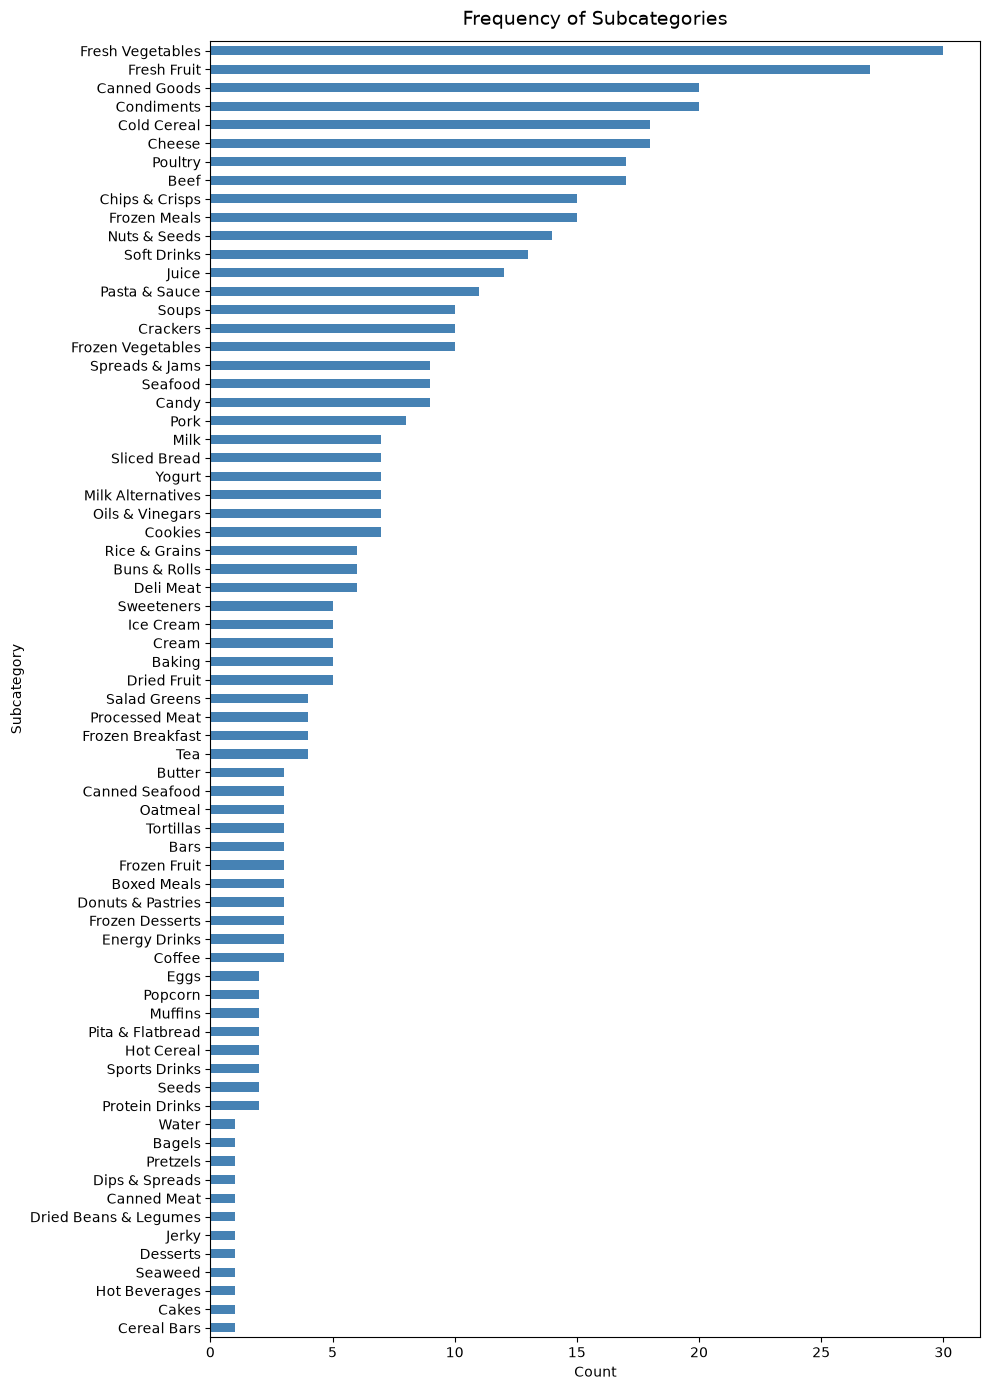

In [5]:
counts = food['Subcategory'].value_counts()

fig, ax = plt.subplots(figsize=(10, 14))
counts.plot(kind='barh', ax=ax, color='steelblue')

ax.set_title('Frequency of Subcategories', fontsize=14, pad=12)
ax.set_xlabel('Count')
ax.set_ylabel('Subcategory')
ax.invert_yaxis()  # most frequent at the top

plt.tight_layout()
plt.show()

In [6]:
top_5_highest_protein_foods = food.sort_values(by='Protein (g)', ascending=False).drop_duplicates(subset=['Subcategory']).head()
top_5_highest_protein_foods

,Food Name,Category,Subcategory,Serving Size,Serving Weight (g),Calories,Protein (g),Total Fat (g),Saturated Fat (g),Total Carbs (g),Dietary Fiber (g),Sugars (g),Sodium (mg),Healthy
290,Great Value Chocolate Protein Shake,Beverages,Protein Drinks,1 bottle (325 mL),325,160,30.0,3.0,0.5,4,1.0,1.0,230,True
90,Great Value Atlantic Salmon Fillets Fresh,Meat & Seafood,Seafood,4 oz (112g),112,230,25.0,14.0,3.0,0,0.0,0.0,70,True
473,Great Value Beef Cubed Steak,Meat & Seafood,Beef,4 oz (112g),112,140,24.0,4.5,1.5,0,0.0,0.0,55,True
455,Tyson All Natural Boneless Skinless Chicken Br...,Meat & Seafood,Poultry,4 oz (112g),112,120,23.0,2.0,0.5,0,0.0,0.0,75,True
309,Great Value Pork Tenderloin,Meat & Seafood,Pork,4 oz (112g),112,120,23.0,3.0,1.0,0,0.0,0.0,55,True


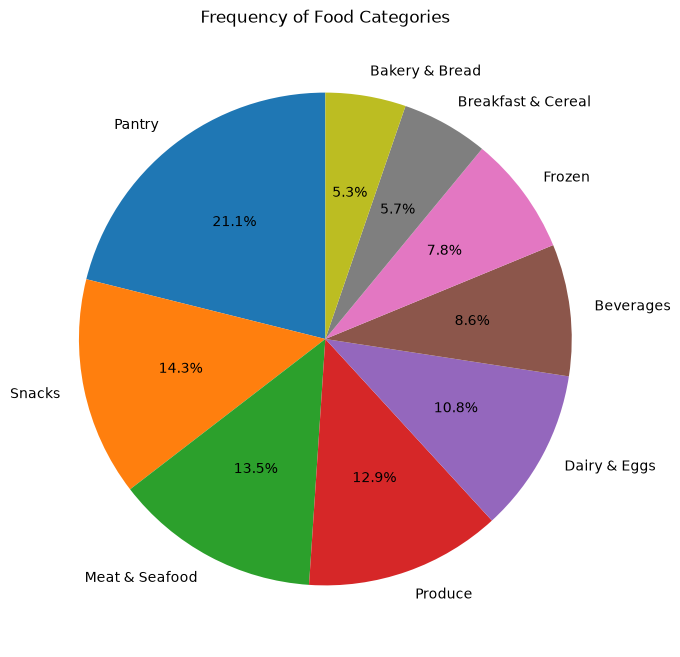

In [7]:
food['Category'].value_counts().plot(
    kind='pie',
    figsize=(8, 8),
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Frequency of Food Categories')
plt.ylabel('')
plt.show()

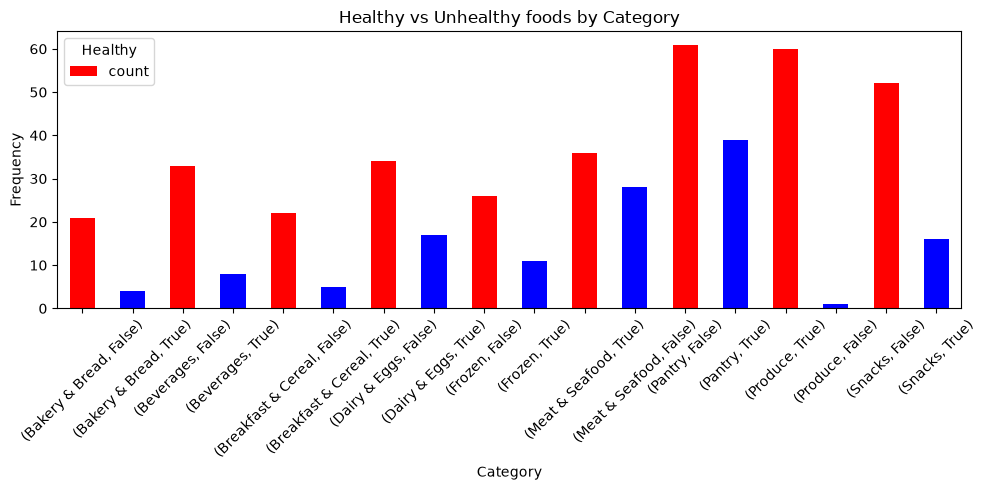

In [8]:
# shows how many foods are healthy and are not healthy grouped by the category - this is fine as long as the predicted meals have a ratio of 1:3
# healthy foods have less sodium and less than 3.5 g of saturated fat
food.groupby('Category')['Healthy'].value_counts().plot(kind="bar", figsize=(10,5), color=['red', 'blue']) 
plt.title('Healthy vs Unhealthy foods by Category')

plt.xlabel('Category')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.legend(title='Healthy')
plt.tight_layout()
plt.show()

In [9]:
# sugary foods to stay away from
top_5_highest_sugary_foods = food.sort_values(by='Sugars (g)', ascending=False).drop_duplicates(subset=['Subcategory']).head()
top_5_highest_sugary_foods

,Food Name,Category,Subcategory,Serving Size,Serving Weight (g),Calories,Protein (g),Total Fat (g),Saturated Fat (g),Total Carbs (g),Dietary Fiber (g),Sugars (g),Sodium (mg),Healthy
404,Monster Energy Drink,Beverages,Energy Drinks,1 can (473 mL),473,210,0.0,0.0,0.0,54,0.0,54.0,370,False
366,Great Value Cream Soda,Beverages,Soft Drinks,1 can (355 mL),355,190,0.0,0.0,0.0,50,0.0,50.0,55,False
340,Great Value Pure Maple Syrup,Pantry,Sweeteners,1/4 cup (60 mL),60,200,0.0,0.0,0.0,52,0.0,48.0,15,False
365,Great Value Prune Juice,Beverages,Juice,8 fl oz (240 mL),240,180,1.0,0.0,0.0,45,2.0,42.0,20,False
447,M&M's Milk Chocolate Candies,Snacks,Candy,1 pack (47g),47,230,2.0,9.0,5.0,34,1.0,30.0,30,False


In [10]:
# healthy low sugar foods
top_5_lowest_sugary_foods = food.sort_values(by='Sugars (g)', ascending=False).drop_duplicates(subset=['Subcategory']).tail()
top_5_lowest_sugary_foods['Healthy']

250     True
1       True
185    False
123     True
143     True
Name: Healthy, dtype: bool

In [11]:
top_5_lowest_sugary_foods = food.sort_values(by='Sugars (g)', ascending=False).drop_duplicates(subset=['Subcategory']).tail()
top_5_lowest_sugary_foods

,Food Name,Category,Subcategory,Serving Size,Serving Weight (g),Calories,Protein (g),Total Fat (g),Saturated Fat (g),Total Carbs (g),Dietary Fiber (g),Sugars (g),Sodium (mg),Healthy
250,Great Value Ground Flaxseed,Pantry,Seeds,2 tbsp (14g),14,70,2.5,5.0,0.5,4,3.5,0.0,5,True
1,Great Value Large White Eggs,Dairy & Eggs,Eggs,1 large egg,50,70,6.0,5.0,1.5,0,0.0,0.0,70,True
185,Great Value Instant Grits Original,Breakfast & Cereal,Hot Cereal,1 packet (28g),28,100,2.0,0.5,0.0,22,1.0,0.0,210,False
123,Great Value Hummus Classic,Dairy & Eggs,Dips & Spreads,2 tbsp (28g),28,70,2.0,5.0,0.5,4,1.0,0.0,115,True
143,Great Value Canned Chicken Breast,Meat & Seafood,Canned Meat,2.5 oz (56g),56,70,12.0,1.5,0.5,0,0.0,0.0,330,True


Text(0, 0.5, 'Protein (g)')

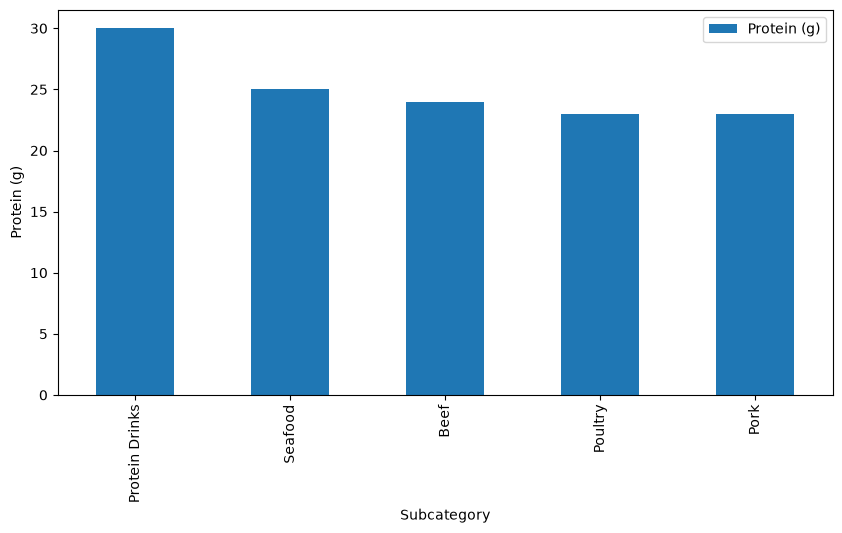

In [12]:
top_5_highest_protein_foods.plot(kind='bar', x='Subcategory', y='Protein (g)', figsize=(10,5))
plt.xlabel('Subcategory')
plt.ylabel('Protein (g)')

In [14]:
# Find the five lowest-protein foods from different subcategories
top_5_lowest_protein_foods = (
    food.sort_values(by='Protein (g)', ascending=True)
    .drop_duplicates(subset=['Subcategory'])
    .head(5)
)

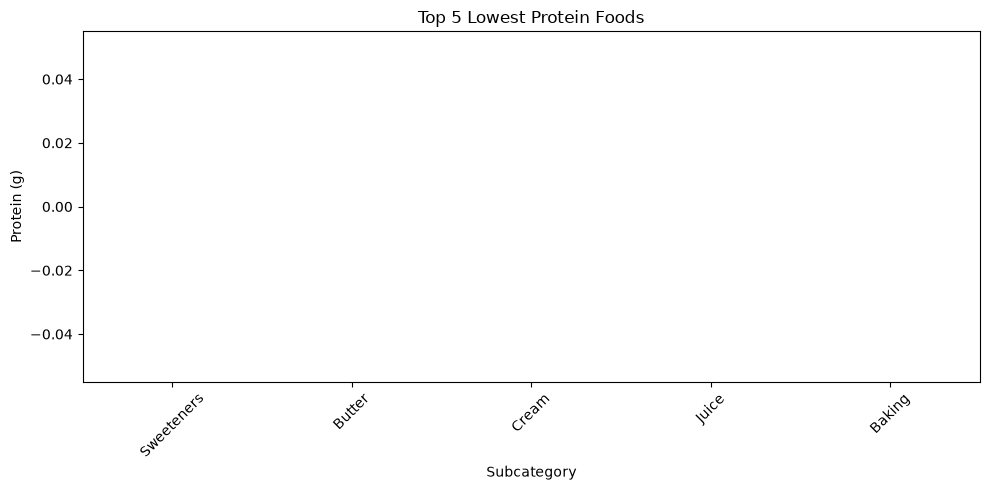

In [15]:
top_5_lowest_protein_foods.plot(
    kind='bar',
    x='Subcategory',
    y='Protein (g)',
    figsize=(10, 5),
    legend=False
)

plt.xlabel('Subcategory')
plt.ylabel('Protein (g)')
plt.title('Top 5 Lowest Protein Foods')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
print(top_5_lowest_protein_foods)
print(top_5_lowest_protein_foods.shape)

                            Food Name      Category Subcategory  \
61             Great Value Pure Honey        Pantry  Sweeteners   
413        Land O'Lakes Salted Butter  Dairy & Eggs      Butter   
76   Great Value Heavy Whipping Cream  Dairy & Eggs       Cream   
74               Great Value Lemonade     Beverages       Juice   
324            Great Value Cornstarch        Pantry      Baking   

         Serving Size  Serving Weight (g)  Calories  Protein (g)  \
61       1 tbsp (21g)                  21        60          0.0   
413      1 tbsp (14g)                  14       100          0.0   
76       1 tbsp (15g)                  15        50          0.0   
74   8 fl oz (240 mL)                 240       110          0.0   
324       1 tbsp (8g)                   8        30          0.0   

     Total Fat (g)  Saturated Fat (g)  Total Carbs (g)  Dietary Fiber (g)  \
61             0.0                0.0               17                0.0   
413           11.0                

In [19]:

# adjusts attributes to fit personal serving size input for (how much did you eat?)

gender = 'M' # or 'W'

activity_level = 'sedentary' #['sedentary', 'lightly active', 'moderately active', 'very active', 'extra active']

age_in_years = 20 # age number ranging from 10-99 in years

height_in_cm = 180  # (how tall are you? in kg)

height_in_m = height_in_cm/100

weight_in_kg = 67

height_in_inches = 62

weight_in_lbs = 115

body_goals = ['lose weight', 'maintain weight', 'gain weight'] # by default will be to maintain weight

food_restriction_selection = food['Subcategory'].values # drop box selection

food_restrictions = []

food_favorites = ['Chocolate', 'Chicken', 'Broccoli'] # list [what do you like to eat?]


In [20]:
# for allerigies, dislikes, religion, vegan, vegeterian
personal_menu = food.copy()

if len(food_restrictions) > 0:
    restriction_filter = (
        personal_menu['Category'].apply(
            lambda x: any(r in x for r in food_restrictions)
        )
        |
        personal_menu['Subcategory'].apply(
            lambda x: any(r in x for r in food_restrictions)
        )
        |
        personal_menu['Food Name'].apply(
            lambda x: any(r in x.lower() for r in food_restrictions)
        )
    )

    personal_menu = personal_menu[~restriction_filter]

personal_menu


,Food Name,Category,Subcategory,Serving Size,Serving Weight (g),Calories,Protein (g),Total Fat (g),Saturated Fat (g),Total Carbs (g),Dietary Fiber (g),Sugars (g),Sodium (mg),Healthy
0,Great Value Whole Milk,Dairy & Eggs,Milk,1 cup (240 mL),244,150,8.0,8.0,5.0,12,0.0,12.0,120,True
1,Great Value Large White Eggs,Dairy & Eggs,Eggs,1 large egg,50,70,6.0,5.0,1.5,0,0.0,0.0,70,True
2,Great Value Unsalted Sweet Cream Butter,Dairy & Eggs,Butter,1 tbsp (14g),14,100,0.0,11.0,7.0,0,0.0,0.0,0,False
3,Great Value Whole Wheat Bread,Bakery & Bread,Sliced Bread,1 slice (38g),38,100,4.0,1.5,0.0,19,3.0,3.0,140,True
4,Great Value Boneless Skinless Chicken Breasts,Meat & Seafood,Poultry,4 oz (112g),112,110,23.0,1.5,0.5,0,0.0,0.0,220,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
469,Marketside Choice Angus Bone-In Ribeye Steak,Meat & Seafood,Beef,4 oz (112g),112,260,20.0,20.0,8.0,0,0.0,0.0,60,False
470,Marketside Choice Angus Flat Iron Steak,Meat & Seafood,Beef,4 oz (112g),112,190,22.0,10.0,4.0,0,0.0,0.0,65,False
471,Marketside Choice Angus Tri-Tip Roast Steak,Meat & Seafood,Beef,4 oz (112g),112,170,22.0,9.0,3.5,0,0.0,0.0,55,True
472,Great Value Beef Top Round Steak,Meat & Seafood,Beef,4 oz (112g),112,130,24.0,3.0,1.0,0,0.0,0.0,50,True


In [21]:
# Calculation (for what did you today?)
# Calculation (for diet plan)
# BMI = weight (kg) ÷ [height (m)]²
# the user should have an option to metric 
metric = True;
if metric:
    if gender == 'M':
        bmi = round(weight_in_kg/(height_in_m**2))
    else:
        women_weight_in_kg = weight_in_kg * 1.09
        bmi = round(women_weight_in_kg/(height_in_m**2))
else:
    if gender == 'M':
        bmi = round((weight_in_lbs/(height_in_inches**2)) * 703)
    else:
        women_weight_in_kg = weight_in_kg * 1.09
        bmi = round(women_weight_in_kg/(height_in_m**2))
bmi

21

In [22]:
# BMI = (weight in pounds ÷ (height in inches × height in inches)) × 703.
if gender == 'M':
    bmi = round((weight_in_lbs/(height_in_inches**2)) * 703)
else:
    women_weight_in_kg = weight_in_kg * 1.09
    bmi = round(women_weight_in_kg/(height_in_m**2))
bmi

21

In [23]:
if bmi >= 19 & bmi <= 24:
    print("Your BMI is:", bmi, "\nYou should maintain your weight.")
elif bmi < 19:
    print("Your BMI is:", bmi, "\nYou should gain weight.")
else:
    print("Your BMI is:", bmi, "\nYou should lose weight.")

Your BMI is: 21 
You should maintain your weight.


In [26]:
# Method to Calculate BMR for calories per day
# Mifflin-St Jeor Equation (1990) – widely used for its accuracy:

if gender == 'M':
    bmr = (10 * weight_in_kg) + (6.25 * height_in_cm) - (5 * age_in_years) + 5
else:
    bmr = (10 * weight_in_kg) + (6.25 * height_in_cm) - (5 * age_in_years) - 161

bmr

1700.0

In [28]:
# Calculation for activity level for calories per day

if activity_level == 'sedentary':
    daily_calories = bmr
elif activity_level == 'lightly active':
    daily_calories = bmr * 1.375
elif activity_level == 'moderately active':
    daily_calories = bmr * 1.55
elif activity_level == 'very active':
    daily_calories = bmr * 1.55
elif activity_level == 'extremely active':
    daily_calories = daily_calories*1.9

daily_calories 

1700.0

In [30]:
# calculation for daily fibers
if gender == 'M':
    daily_fiber = (daily_calories/1000)*14 # in grams, why 1000? why 14?
else:
    daily_fiber: daily_calories = (10 * weight_in_kg) + (6.25 * height_in_cm) - (5 * age_in_years) - 161 # in grams

In [ ]:
# Sources
# https://www.bing.com/search?q=how+to+calculate+activity+level+for+calories&qs=UT&pq=how+to+calculate+activity+level&sk=HS1&sc=8-31&cvid=81267C6D32024FCDBFE4503967755D6D&FORM=QBRE&sp=2&lq=0